**Eurovision Voting Blocs Across Eras (1975–2024)**

# 04 - Jury vs Televote

**Objectives**
- Compare the voting networks of professional juries and of the public in P4 (2016–2024)
- Test whether blocs, mutual support and the effect of geography differ between the two channels
- Produce the figures and tables for this comparison

**Input:** `data/02_network_construction/p4_channels/` and the P4 files in `data/02_network_construction/` (notebook 02)

**Output:** tables in `data/04_jury_vs_televote/`, Figures 4–6 in `data/04_jury_vs_televote/figures/`

### Why this comparison matters

Comparing periods (e.g. P1 with P2) mixes several changes at once: the voting rule, the passing of time and the arrival of about twenty new countries. Since 2016, however, every country gives two separate sets of points in the same final: one from a jury of music professionals and one from the public. Same year, same songs, same participants: any difference between the two networks can only come from who votes. This makes P4 a natural experiment for the second part of H2 ("the effect of borders and language shifts between jury and televote").

All measures below are the same as in notebook 03, applied to three P4 networks:

| Network | Points used |
|---|---|
| Jury | `jury_points` only |
| Televote | `tele_points` only |
| Combined | jury + televote (the P4 network used in the rest of the project) |

In [1]:
import os
import itertools

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from sklearn.metrics import normalized_mutual_info_score

from helper_functions import (best_louvain, shuffle_rows, qap_r,
                              INK, INK2, MUTED, GRID, CH_COLOR, CH_LABEL, CH_TICK, style, label)

## 1. Setup

### 1.1. Paths and Settings

In [2]:
DATA_PROC = os.path.join("..", "data", "02_network_construction")
DATA_CHANNELS = os.path.join(DATA_PROC, "p4_channels")
RESULTS = os.path.join("..", "data", "04_jury_vs_televote")
FIGURES = os.path.join(RESULTS, "figures")
os.makedirs(FIGURES, exist_ok=True)

CHANNELS = ["jury", "televote", "combined"]
SEED = 2024        # same seed as the null models of notebook 03
N_PERM = 500       # null networks for the modularity test
N_QAP = 2000       # permutations for QAP
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8})   # figure style (same as notebook 03)

### 1.2. Load the Networks

In [4]:
W = {"combined": pd.read_csv(os.path.join(DATA_PROC, "P4_adj_topk3.csv"), index_col=0)}
B = {"combined": pd.read_csv(os.path.join(DATA_PROC, "P4_adj_binary_t05.csv"), index_col=0)}
for ch in ["jury", "televote"]:
    W[ch] = pd.read_csv(os.path.join(DATA_CHANNELS, f"P4_{ch}_adj_topk3.csv"), index_col=0)
    B[ch] = pd.read_csv(os.path.join(DATA_CHANNELS, f"P4_{ch}_adj_binary_t05.csv"), index_col=0)
co_years = pd.read_csv(os.path.join(DATA_CHANNELS, "P4_jury_co_years.csv"), index_col=0)

nodes = list(W["combined"].index)
assert all(list(W[c].index) == nodes and list(B[c].index) == nodes for c in CHANNELS)
print(f"{len(nodes)} countries in P4")

45 countries in P4


In [5]:
contig = pd.read_csv(os.path.join(DATA_PROC, "P4_cepii_contig.csv"), index_col=0).loc[nodes, nodes].values.astype(float)
comlang = pd.read_csv(os.path.join(DATA_PROC, "P4_cepii_comlang.csv"), index_col=0).loc[nodes, nodes].values.astype(float)

## 2. Blocs

### 2.1. Louvain and Modularity

Same method as notebook 03 (`best_louvain`, best of 100 runs), applied to the weighted network of each channel.

In [6]:
graphs = {ch: nx.from_pandas_adjacency(W[ch], create_using=nx.DiGraph) for ch in CHANNELS}

In [7]:
partitions, q_obs = {}, {}
for ch in CHANNELS:
    blocs, q_obs[ch] = best_louvain(graphs[ch])
    partitions[ch] = sorted(blocs, key=len, reverse=True)
    print(f"\n{CH_LABEL[ch]}: {len(partitions[ch])} blocs, Q = {q_obs[ch]:.3f}")
    for i, b in enumerate(partitions[ch], start=1):
        print(f"  Bloc {i} ({len(b)}): {', '.join(sorted(b))}")


Jury: 3 blocs, Q = 0.169
  Bloc 1 (20): AUS, AUT, BEL, BGR, CHE, CZE, DEU, DNK, ESP, EST, FIN, FRA, IRL, ISL, ISR, LUX, NLD, NOR, PRT, SWE
  Bloc 2 (13): BIH, BLR, GBR, GEO, HRV, HUN, LTU, LVA, MKD, POL, SRB, SVN, UKR
  Bloc 3 (12): ALB, ARM, AZE, CYP, GRC, ITA, MDA, MLT, MNE, ROU, RUS, SMR



Televote: 4 blocs, Q = 0.251
  Bloc 1 (15): AUS, BEL, DNK, EST, FIN, GBR, HUN, IRL, ISL, LTU, LVA, NLD, NOR, POL, SWE
  Bloc 2 (13): ALB, AUT, BIH, CHE, DEU, HRV, ITA, MKD, MLT, MNE, SMR, SRB, SVN
  Bloc 3 (9): ARM, AZE, BLR, CYP, CZE, GEO, GRC, RUS, UKR
  Bloc 4 (8): BGR, ESP, FRA, ISR, LUX, MDA, PRT, ROU



Combined: 4 blocs, Q = 0.207
  Bloc 1 (16): AUS, AUT, BEL, CHE, CZE, DEU, DNK, FIN, GBR, HUN, IRL, ISL, NLD, NOR, PRT, SWE
  Bloc 2 (15): ARM, AZE, BGR, BLR, CYP, ESP, FRA, GEO, GRC, ISR, LUX, MDA, ROU, RUS, SMR
  Bloc 3 (9): ALB, BIH, HRV, ITA, MKD, MLT, MNE, SRB, SVN
  Bloc 4 (5): EST, LTU, LVA, POL, UKR


### 2.2. Are the Blocs Real? Permutation Test

Same test as notebook 03: 500 null networks (`shuffle_rows`), z-score and p-value. As in the sensitivity check of notebook 03, the observed Q comes from the best of 10 runs, the same procedure used on the null networks.

In [9]:
perm_rows = []
for ch in CHANNELS:
    rng = np.random.default_rng(SEED)
    nulls = np.array([best_louvain(nx.from_pandas_adjacency(shuffle_rows(W[ch], rng), create_using=nx.DiGraph), n_runs=10)[1]
                      for _ in range(N_PERM)])
    q10 = best_louvain(graphs[ch], n_runs=10)[1]
    perm_rows.append({"channel": ch, "n_blocs": len(partitions[ch]), "Q_observed": round(q_obs[ch], 3),
                      "Q_null_mean": round(nulls.mean(), 3), "Q_null_max": round(nulls.max(), 3),
                      "z_score": round((q10 - nulls.mean()) / nulls.std(), 1),
                      "p_value": round((np.sum(nulls >= q10) + 1) / (N_PERM + 1), 4)})
perm_table = pd.DataFrame(perm_rows)
perm_table

,channel,n_blocs,Q_observed,Q_null_mean,Q_null_max,z_score,p_value
0,jury,3,0.169,0.153,0.176,2.3,0.016
1,televote,4,0.251,0.173,0.199,9.4,0.002
2,combined,4,0.207,0.153,0.179,7.4,0.002


One row per channel. `n_blocs` and `Q_observed` come from the partition of the best-of-100-runs-Louvain; `Q_null_mean` and `Q_null_max` are the average and the highest Q among the 500 null networks; `z_score` and `p_value` compare the null networks with the observed Q of the best of 10 runs.

The televote blocs are far above chance: z = 9.4 and no null network reaches the observed Q, so the p-value is the smallest possible (1/501 ≈ 0.002). The combined network is close behind (z = 7.4). The jury blocs are only slightly above chance: z = 2.3, and 7 of the 500 null networks reach its Q (p = 0.016); the highest null Q (0.176) is even above the jury's observed Q (0.169).

### 2.3. Do Jury and Televote Find the Same Blocs? (NMI)

NMI between the partitions of each pair of channels, as in notebook 03 (1 = identical divisions, close to 0 = unrelated).

In [10]:
bloc_of = {ch: {c: i for i, b in enumerate(partitions[ch], start=1) for c in b} for ch in CHANNELS}
nmi_table = pd.DataFrame([{"pair": f"{CH_LABEL[a]} vs {CH_LABEL[b]}",
                           "NMI": round(normalized_mutual_info_score([bloc_of[a][c] for c in nodes],
                                                                     [bloc_of[b][c] for c in nodes]), 3)}
                          for a, b in itertools.combinations(CHANNELS, 2)])
nmi_table

,pair,NMI
0,Jury vs Televote,0.216
1,Jury vs Combined,0.355
2,Televote vs Combined,0.508


One row per pair of channels. Jury and televote share little of their bloc structure (NMI = 0.22). The combined network is closer to the televote (0.51) than to the jury (0.36), so the P4 blocs used in the rest of the project mostly reflect the public's vote.

## 3. Mutual Support

We compute the same three measures as in notebook 03 (density, reciprocity and reciprocity vs random) for each channel. As in notebook 03, they use the binary networks of stable ties, because they only ask whether a tie exists, not how strong it is.

In [11]:
mutual_rows = []
for ch in CHANNELS:
    G = nx.from_pandas_adjacency(B[ch], create_using=nx.DiGraph)
    dens, rec = nx.density(G), nx.reciprocity(G)
    mutual_rows.append({"channel": ch, "stable_ties": G.number_of_edges(), "density": round(dens, 3),
                        "reciprocity": round(rec, 3), "reciprocity_vs_random": round(rec / dens, 1),
                        "mutual_pairs": sum(1 for u, v in G.edges() if G.has_edge(v, u)) // 2,
                        "isolated": len(list(nx.isolates(G)))})
mutual_table = pd.DataFrame(mutual_rows)
mutual_table

,channel,stable_ties,density,reciprocity,reciprocity_vs_random,mutual_pairs,isolated
0,jury,71,0.036,0.085,2.4,3,6
1,televote,111,0.056,0.216,3.9,12,2
2,combined,101,0.051,0.198,3.9,10,2


One row per channel. `stable_ties` is the number of ties A → B in the binary network and `density` that number divided by the 1,980 possible ties among the 45 countries; `mutual_pairs` counts the pairs with stable ties in both directions and `isolated` the countries with no stable tie, given or received.

The televote has more stable ties than the jury (111 vs 71), and many more of them are returned: 12 mutual pairs and reciprocity 0.216, against 3 pairs and 0.085 for the jury. Taking density into account, mutual ties are 3.9 times more frequent than chance in the televote and 2.4 times in the jury. Six countries have no stable tie at all in the jury network, against two in the televote.

## 4. Geography and Language

### 4.1. QAP Correlation

We want the correlation between two country-by-country tables: the voting weights and an attribute (1 if the two countries share a border, 0 otherwise). An ordinary correlation test treats each pair of countries as a separate, independent observation. In a voting network this is not true. For example, the 44 votes given by Greece (Greece → Albania, Greece → Armenia, …) all come from the same voter: Greece can only put three countries in its top 3 each year, so if it always picks the same ones, that single habit sets all 44 values at once. The ordinary test would count this one habit as 44 separate pieces of evidence, and would find significant correlations too easily.

QAP (Quadratic Assignment Procedure) solves this by building the "chance" distribution differently: it shuffles the countries (rows and columns of the voting table together) and recomputes the correlation many times. Each shuffled table keeps the full structure of the network (who votes a lot, who is popular), but breaks the link with the real borders. The p-value is the share of shuffles that reach the observed correlation. The test is done by `qap_r` (in `helper_functions.py`), with 2,000 shuffles.

In [13]:
qap_rows = []
for ch in CHANNELS:
    for name, X in [("shared border", contig), ("shared language", comlang)]:
        r, p = qap_r(W[ch].values, X)
        qap_rows.append({"channel": ch, "attribute": name, "QAP_r": round(r, 3), "p_value": round(p, 4)})
qap_table = pd.DataFrame(qap_rows)
qap_table.pivot(index="attribute", columns="channel", values="QAP_r")[CHANNELS]

channel,jury,televote,combined
attribute,,,
shared border,0.098,0.287,0.249
shared language,0.100,0.152,0.176


Each value is the QAP correlation between a channel's voting weights and the attribute. All six p-values (in `qap_table`) are 0.0005, the smallest possible with 2,000 shuffles (1/2001), so every correlation is above chance.

Sharing a border matters about three times more for the televote (0.287) than for the jury (0.098). Sharing a language has a weaker effect, also larger for the televote (0.152 vs 0.100). For the jury, border and language have about the same small effect.

### 4.2. A More Intuitive View: Weight Given to Neighbours

The same question in plain numbers: on average, how often does a country put a neighbour in its top 3, compared with a country it does not border? Only pairs that met in at least 3 finals are used, to avoid shares based on one or two votes.

In [14]:
pairs = []
for i, u in enumerate(nodes):
    for j, v in enumerate(nodes):
        if u != v and co_years.loc[u, v] >= 3:
            pairs.append({"from": u, "to": v, "co_years": int(co_years.loc[u, v]), "neighbours": bool(contig[i, j]),
                          "jury": W["jury"].loc[u, v], "televote": W["televote"].loc[u, v]})
pairs = pd.DataFrame(pairs)

neighbour_table = pairs.groupby("neighbours")[["jury", "televote"]].mean().round(3)
neighbour_table.loc["ratio (neighbour / not)"] = (neighbour_table.loc[True] / neighbour_table.loc[False]).round(1)
neighbour_table

,jury,televote
neighbours,,
False,0.114,0.106
True,0.176,0.333
ratio (neighbour / not),1.500,3.100


Each value is the average weight from voter to receiver: the share of their shared finals in which the receiver was in the voter's top 3. The last row divides the value for neighbours by the value for non-neighbours.

Both channels put a non-neighbour in their top 3 in about 11% of the finals. For a neighbour, juries do it in 18% of the finals (1.5 times as often), while the public does it in a third of the finals (3.1 times as often).

## 5. How Similar Are the Two Channels?

- QAP correlation jury vs televote: correlation between the two weight tables, tested with QAP;
- Overlap of stable ties: ties present in both binary networks, in only one, and their Jaccard index (shared ÷ present in at least one).

In [15]:
r_jt, p_jt = qap_r(W["jury"].values, W["televote"].values)
ties = {ch: {(u, v) for u in nodes for v in nodes if B[ch].loc[u, v]} for ch in ["jury", "televote"]}
similarity = pd.DataFrame([{"QAP_r_jury_televote": round(r_jt, 3), "p_value": round(p_jt, 4),
                            "ties_both": len(ties["jury"] & ties["televote"]),
                            "ties_jury_only": len(ties["jury"] - ties["televote"]),
                            "ties_televote_only": len(ties["televote"] - ties["jury"]),
                            "jaccard": round(len(ties["jury"] & ties["televote"]) / len(ties["jury"] | ties["televote"]), 3)}])
similarity.T

,0
QAP_r_jury_televote,0.2510
p_value,0.0005
ties_both,19.0000
ties_jury_only,52.0000
ties_televote_only,92.0000
jaccard,0.1170


`QAP_r_jury_televote` and `p_value` are the correlation between the jury and the televote weight tables and its QAP p-value. `ties_both`, `ties_jury_only` and `ties_televote_only` count the stable ties present in both binary networks, only in the jury network and only in the televote network; `jaccard` is `ties_both` divided by all the ties present in at least one of them.

The two channels are related (r = 0.25, p = 0.0005, the smallest possible), but weakly. Only 19 stable ties appear in both networks, against 52 that only the jury has and 92 that only the televote has, so only 12% of all stable ties are shared (Jaccard = 0.117).

## 6. Where Do They Disagree Most?

Pairs (with at least 3 shared finals) with the largest difference between the share of years in the televote top 3 and in the jury top 3.

In [16]:
pairs["diff"] = pairs["televote"] - pairs["jury"]
top_public = pairs.nlargest(8, "diff")
top_jury = pairs.nsmallest(8, "diff")
pd.concat([top_public, top_jury])[["from", "to", "co_years", "neighbours", "jury", "televote", "diff"]].round(2)

,from,to,co_years,neighbours,jury,televote,diff
804,ISR,RUS,3,False,0.00,1.00,1.00
907,LVA,RUS,3,True,0.00,1.00,1.00
1310,SVN,HRV,4,True,0.00,1.00,1.00
729,IRL,LTU,6,False,0.00,0.83,0.83
900,LVA,LTU,6,True,0.17,1.00,0.83
462,EST,FIN,5,False,0.20,1.00,0.80
586,GEO,ARM,5,True,0.20,1.00,0.80
1165,PRT,MDA,5,False,0.00,0.80,0.80
345,CZE,SWE,8,False,0.75,0.00,-0.75
712,IRL,BGR,4,False,0.75,0.00,-0.75


The first 8 rows are the pairs the public favours much more than the jury (`diff` > 0), the last 8 the pairs the jury favours more (`diff` < 0). `jury` and `televote` are the share of shared finals in which `to` was in the top 3 of `from`, and `co_years` is the number of shared finals.

Half of the public's pairs are neighbours (Slovenia → Croatia, Latvia → Lithuania, Georgia → Armenia, Latvia → Russia), and most of the others match close languages or large immigrant communities (Estonia → Finland, Israel → Russia, Ireland → Lithuania, Portugal → Moldova). Only 2 of the jury's 8 pairs are neighbours (Russia → Azerbaijan, Bulgaria → Greece), and the rest have no obvious link. Many pairs met in only 3 to 5 finals, so single values should be read with care.

## 7. Export Tables

In [17]:
perm_table.to_csv(os.path.join(RESULTS, "modularity_permutation_test.csv"), index=False)
nmi_table.to_csv(os.path.join(RESULTS, "nmi_blocs.csv"), index=False)
mutual_table.to_csv(os.path.join(RESULTS, "mutual_support.csv"), index=False)
qap_table.to_csv(os.path.join(RESULTS, "qap_border_language.csv"), index=False)
neighbour_table.to_csv(os.path.join(RESULTS, "weight_to_neighbours.csv"))
similarity.to_csv(os.path.join(RESULTS, "channel_similarity.csv"), index=False)
pairs.sort_values("diff").to_csv(os.path.join(RESULTS, "pair_differences.csv"), index=False)
pd.DataFrame([{"channel": ch, "bloc_id": i, "iso3": c} for ch in CHANNELS
              for i, b in enumerate(partitions[ch], start=1) for c in sorted(b)]
             ).to_csv(os.path.join(RESULTS, "bloc_membership_by_channel.csv"), index=False)

## 8. Figures

### 8.1. Figure 4: The Two Channels in Three Numbers

(a) strength of the blocs, (b) mutual support, (c) how much more a neighbour is favoured than a non-neighbour.

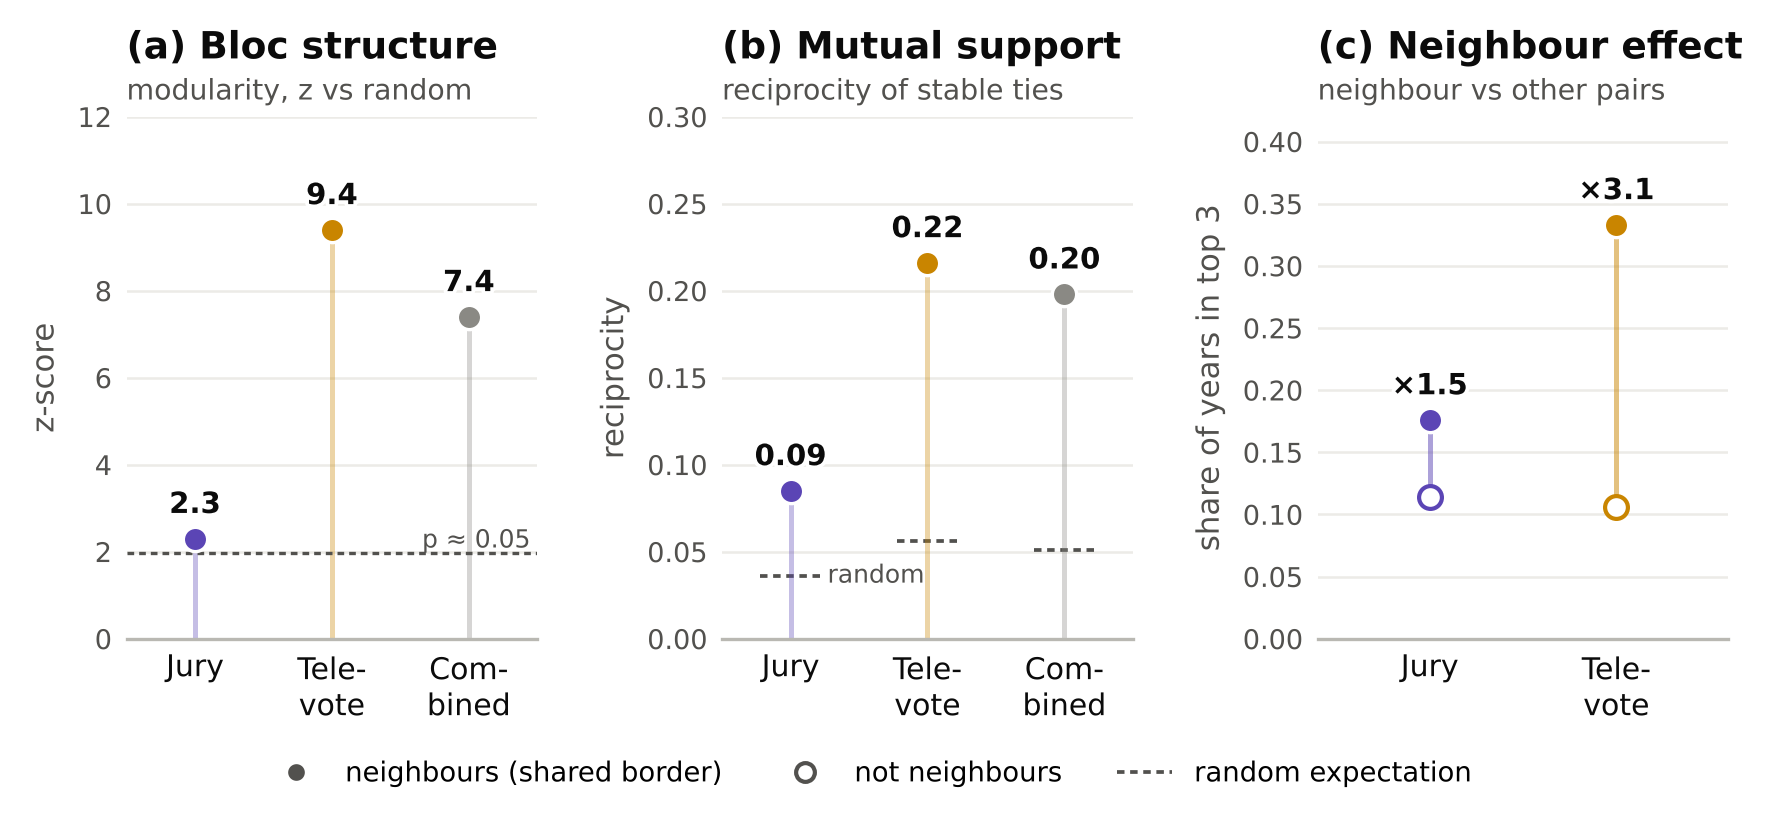

In [18]:
z = perm_table.set_index("channel")["z_score"]
rec = mutual_table.set_index("channel")["reciprocity"]
dens = mutual_table.set_index("channel")["density"]
xs = np.arange(3)

fig, axes = plt.subplots(1, 3, figsize=(5.9, 2.9), dpi=300)

# (a) bloc strength
ax = axes[0]
for x, ch in zip(xs, CHANNELS):
    ax.vlines(x, 0, z[ch], color=CH_COLOR[ch], lw=1.2, alpha=0.35)
    ax.scatter(x, z[ch], s=34, color=CH_COLOR[ch], edgecolor="white", lw=0.8, zorder=3)
    label(ax, x, z[ch], f"{z[ch]:.1f}")
ax.axhline(1.96, color=INK2, lw=0.8, ls=(0, (2, 1.5)))
ax.text(2.45, 1.96, "p ≈ 0.05", fontsize=6, color=INK2, ha="right", va="bottom")
ax.set_ylim(0, 12); ax.set_xlim(-0.5, 2.5)
ax.set_xticks(xs); ax.set_xticklabels([CH_TICK[c] for c in CHANNELS], fontsize=7.2, color=INK)
style(ax, "(a) Bloc structure", "modularity, z vs random", "z-score")

# (b) mutual support, with the random expectation (= density) as a dashed tick
ax = axes[1]
for x, ch in zip(xs, CHANNELS):
    ax.hlines(dens[ch], x - 0.22, x + 0.22, color=INK2, lw=0.9, ls=(0, (2, 1.5)))
    ax.vlines(x, 0, rec[ch], color=CH_COLOR[ch], lw=1.2, alpha=0.35)
    ax.scatter(x, rec[ch], s=34, color=CH_COLOR[ch], edgecolor="white", lw=0.8, zorder=3)
    label(ax, x, rec[ch], f"{rec[ch]:.2f}")
ax.text(0.27, dens["jury"], "random", fontsize=6, color=INK2, ha="left", va="center")
ax.set_ylim(0, 0.3); ax.set_xlim(-0.5, 2.5)
ax.set_xticks(xs); ax.set_xticklabels([CH_TICK[c] for c in CHANNELS], fontsize=7.2, color=INK)
style(ax, "(b) Mutual support", "reciprocity of stable ties", "reciprocity")

# (c) neighbour effect: hollow = not neighbours, filled = neighbours
ax = axes[2]
for x, ch in zip([0, 1], ["jury", "televote"]):
    lo, hi = neighbour_table.loc[False, ch], neighbour_table.loc[True, ch]
    ax.vlines(x, lo, hi, color=CH_COLOR[ch], lw=1.2, alpha=0.5)
    ax.scatter(x, lo, s=30, facecolor="white", edgecolor=CH_COLOR[ch], lw=1.0, zorder=3)
    ax.scatter(x, hi, s=34, color=CH_COLOR[ch], edgecolor="white", lw=0.8, zorder=3)
    label(ax, x, hi, f"×{hi / lo:.1f}")
ax.set_ylim(0, 0.42); ax.set_xlim(-0.6, 1.6)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Jury", "Tele-\nvote"], fontsize=7.2, color=INK)
style(ax, "(c) Neighbour effect", "neighbour vs other pairs", "share of years in top 3")

handles = [Line2D([], [], marker="o", ls="", mfc=INK2, mec="white", ms=5, label="neighbours (shared border)"),
           Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, ms=4.5, label="not neighbours"),
           Line2D([], [], color=INK2, lw=0.9, ls=(0, (2, 1.5)), label="random expectation")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=6.6, frameon=False, bbox_to_anchor=(0.5, 0.0))
plt.subplots_adjust(left=0.08, right=0.985, top=0.80, bottom=0.2, wspace=0.45)
fig.savefig(os.path.join(FIGURES, "fig4_p4_jury_vs_televote.pdf"), facecolor="white")
fig.savefig(os.path.join(FIGURES, "fig4_p4_jury_vs_televote.png"), dpi=300, facecolor="white")
plt.show()

### 8.2. Figure 5: Blocs of Each Channel on the Map

Same schematic map as Figure 1 (notebook 03). Each channel's blocs are coloured after the bloc of the combined P4 network they overlap most, so that colours mean the same thing in both panels. Lines are stable ties; darker lines are mutual ties.

In [19]:
POS = {
 "ISL":(3,90),
 "NOR":(33,84),"SWE":(44,84),"FIN":(57,88),"EST":(60,80),
 "IRL":(9,70),"GBR":(18,66),"DNK":(36,74),"LVA":(62,73),"LTU":(58,67),"RUS":(82,74),
 "NLD":(28,64),"DEU":(39,63),"POL":(50,62),"BLR":(69,64),
 "BEL":(24,57),"LUX":(30,53),"CZE":(42,56),"UKR":(72,55),
 "FRA":(17,49),"CHE":(28,45),"AUT":(40,49),"SVK":(49,53),"HUN":(54,47),"MDA":(77,47),
 "MCO":(22,39),"SVN":(38,42),"HRV":(45,39),"ROU":(66,41),
 "AND":(12,38),"SMR":(33,35),"BIH":(46,32),"YUG":(52,36),"SCG":(52,38),"SRB":(57,31),
 "PRT":(2,28),"ESP":(10,29),"ITA":(30,28),"MNE":(46,25),"MKD":(58,24),"BGR":(66,32),
 "GEO":(86,37),"AZE":(96,33),"ARM":(88,28),
 "ALB":(51,19),"TUR":(74,22),"GRC":(60,15),"MLT":(33,14),"CYP":(74,10),"ISR":(84,5),
 "MAR":(6,14),"AUS":(97,4)}

In [20]:
P4_LINEAGES = {1: ("Northern & Western", "#2a78d6", "o"),       # colours and shapes of Figure 1
               2: ("Post-Soviet & Caucasus", "#b0307a", "D"),
               3: ("Ex-Yugoslav & Balkan", "#1baf7a", "^"),
               4: ("Baltic–Poland–Ukraine", "#8a8984", "h")}
EXTRA = ("Southern & Western", "#eb6834", "s")

def colour_blocs(blocs):
    # match each bloc to the combined bloc with the highest Jaccard overlap; a second match gets EXTRA
    used, styles = set(), {}
    for i, b in enumerate(blocs, start=1):
        jac = {j: len(b & set(cb)) / len(b | set(cb)) for j, cb in enumerate(partitions["combined"], start=1)}
        best = max(jac, key=jac.get)
        styles[i] = EXTRA if best in used else P4_LINEAGES[best]
        used.add(best)
    return styles

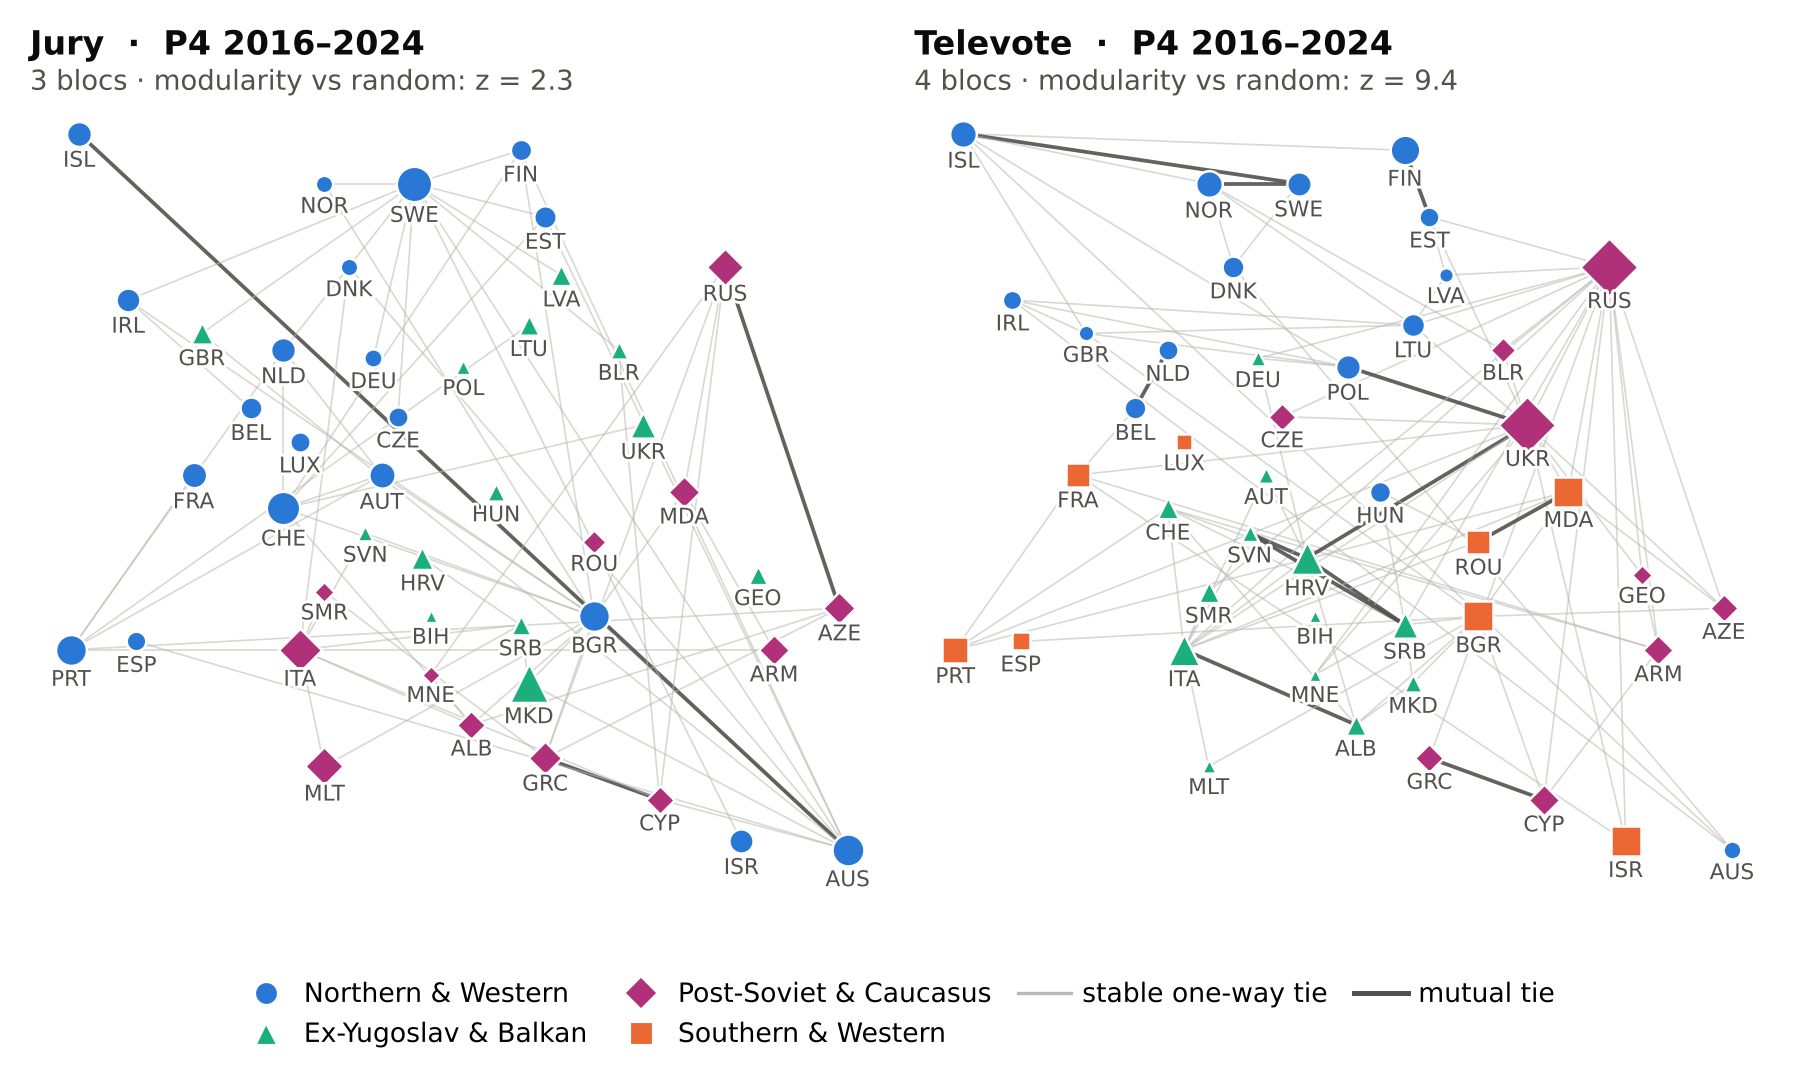

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(5.9, 3.6), dpi=300)
legend_items = {}
for ax, ch in zip(axes, ["jury", "televote"]):
    G, Gb = graphs[ch], nx.from_pandas_adjacency(B[ch], create_using=nx.DiGraph)
    instr = {c: v / (len(nodes) - 1) for c, v in G.in_degree(weight="weight")}
    styles = colour_blocs(partitions[ch])
    for u, v in Gb.edges():
        mutual = Gb.has_edge(v, u)
        if mutual and u > v:          # draw each mutual pair once
            continue
        (x1, y1), (x2, y2) = POS[u], POS[v]
        ax.plot([x1, x2], [y1, y2], color=INK2 if mutual else MUTED, lw=0.9 if mutual else 0.4,
                alpha=0.9 if mutual else 0.55, zorder=1, solid_capstyle="round")
    for i, b in enumerate(partitions[ch], start=1):
        name, col, mk = styles[i]
        legend_items[name] = (col, mk)
        for c in b:
            x, y = POS[c]
            size = 10 + 200 * instr[c]
            ax.scatter(x, y, s=size, c=col, marker=mk, edgecolors="white", linewidths=0.6, zorder=3)
            ax.annotate(c, (x, y), xytext=(0, -(np.sqrt(size) / 2 + 1.0)), textcoords="offset points",
                        ha="center", va="top", fontsize=5.2, color=INK2, zorder=4,
                        path_effects=[pe.withStroke(linewidth=1.4, foreground="white")])
    zrow = perm_table.set_index("channel").loc[ch]
    ax.set_title(f"{CH_LABEL[ch]}  ·  P4 2016–2024", loc="left", fontsize=8, color=INK, fontweight="bold", pad=11)
    ax.text(0, 1.005, f"{len(partitions[ch])} blocs · modularity vs random: z = {zrow['z_score']}", transform=ax.transAxes,
            fontsize=6.6, color=INK2, va="bottom")
    ax.set_xlim(-3, 101); ax.set_ylim(-2, 94); ax.axis("off")

handles = [Line2D([], [], marker=mk, ls="", markerfacecolor=col, markeredgecolor="white", markersize=6, label=name)
           for name, (col, mk) in legend_items.items()]
handles += [Line2D([], [], color=MUTED, lw=0.8, label="stable one-way tie"),
            Line2D([], [], color=INK2, lw=1.2, label="mutual tie")]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=6.4, frameon=False, bbox_to_anchor=(0.5, 0.0),
           handletextpad=0.4, columnspacing=1.0)
plt.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.16, wspace=0.04)
fig.savefig(os.path.join(FIGURES, "fig5_p4_bloc_maps_jury_televote.pdf"), facecolor="white")
fig.savefig(os.path.join(FIGURES, "fig5_p4_bloc_maps_jury_televote.png"), dpi=300, facecolor="white")
plt.show()

### 8.3. Figure 6: Pairs Where Jury and Televote Disagree Most

Each row is a pair *voter → receiver*. The two dots show the share of finals in which the receiver was in the voter's top 3, according to the jury and to the televote; the line is the gap between them.

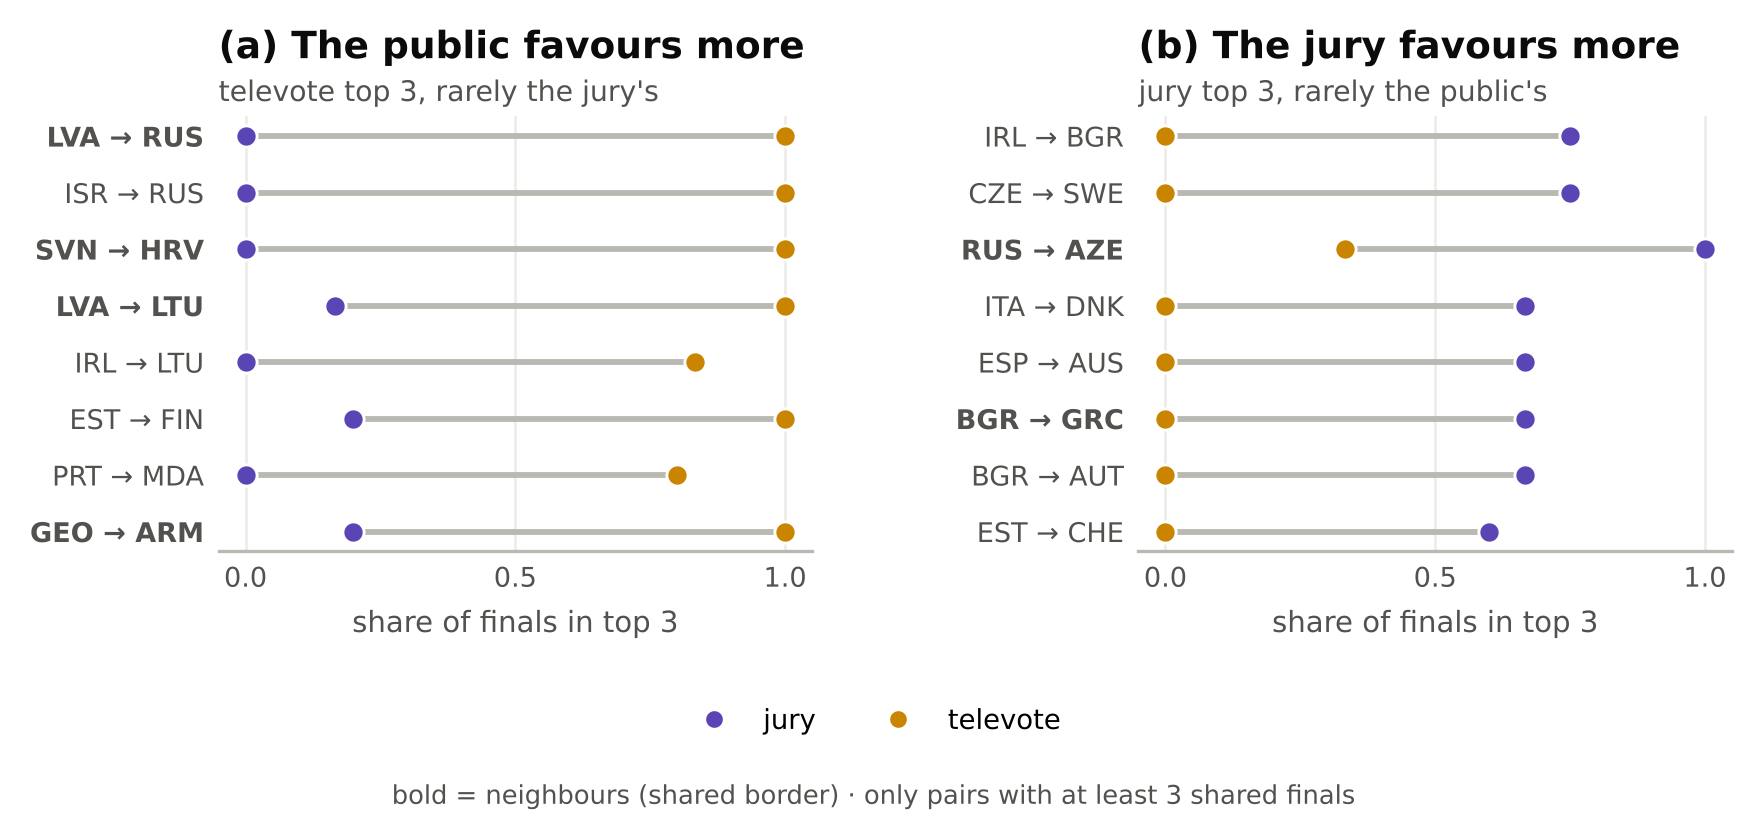

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(5.9, 2.9), dpi=300, sharex=True)
panels = [(top_public.sort_values("diff"), "(a) The public favours more", "televote top 3, rarely the jury's"),
          (top_jury.sort_values("diff", ascending=False), "(b) The jury favours more", "jury top 3, rarely the public's")]
for ax, (d, title, subtitle) in zip(axes, panels):
    y = np.arange(len(d))
    ax.hlines(y, d["jury"], d["televote"], color=MUTED, lw=1.4, zorder=1)
    ax.scatter(d["jury"], y, s=26, color=CH_COLOR["jury"], edgecolor="white", lw=0.7, zorder=3)
    ax.scatter(d["televote"], y, s=26, color=CH_COLOR["televote"], edgecolor="white", lw=0.7, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{a} → {b}" for a, b in zip(d["from"], d["to"])], fontsize=6.6, color=INK)
    for tick, nb in zip(ax.get_yticklabels(), d["neighbours"]):
        tick.set_fontweight("bold" if nb else "normal")      # bold = neighbours
    ax.set_xlim(-0.05, 1.05); ax.set_xticks([0, 0.5, 1]); ax.tick_params(axis="x", labelsize=6.5, colors=INK2)
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
    style(ax, title, subtitle)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("share of finals in top 3", fontsize=7, color=INK2)
handles = [Line2D([], [], marker="o", ls="", mfc=CH_COLOR["jury"], mec="white", ms=5, label="jury"),
           Line2D([], [], marker="o", ls="", mfc=CH_COLOR["televote"], mec="white", ms=5, label="televote")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=6.6, frameon=False, bbox_to_anchor=(0.5, 0.06))
fig.text(0.5, 0.01, "bold = neighbours (shared border) · only pairs with at least 3 shared finals", fontsize=6.2, color=INK2, ha="center")
plt.subplots_adjust(left=0.13, right=0.985, top=0.80, bottom=0.30, wspace=0.55)
fig.savefig(os.path.join(FIGURES, "fig6_p4_largest_disagreements.pdf"), facecolor="white")
fig.savefig(os.path.join(FIGURES, "fig6_p4_largest_disagreements.png"), dpi=300, facecolor="white")
plt.show()

## 9. Interpretation

- The blocs of P4 come mainly from the public. The televote network has a strong bloc structure (z ≈ 9), while the jury network is only marginally above chance (z ≈ 2). The combined network, used in the rest of the project, behaves like the televote and its blocs are closer to the televote blocs than to the jury blocs (NMI).
- Mutual support is a televote phenomenon. Reciprocity is about 0.22 for the televote and 0.09 for the jury, which has only three mutual pairs.
- Geography matters much more to the public. The correlation with shared borders is about three times higher for the televote. The public puts a neighbour in its top 3 about three times as often as a non-neighbour; for juries the ratio is about 1.5. Shared language has a weaker effect in both channels.
- The two channels see different networks. Few stable ties are shared and the bloc partitions are very different. The pairs the public favours are neighbours or countries with large diasporas and historical links (e.g. Romania → Moldova, Latvia → Lithuania, Slovenia → Croatia), while juries favour pairs without obvious proximity, consistent with a more song-oriented judgement.

**Caveats.** Eight finals only; Russia takes part only until 2021; in 2022 the EBU replaced six juries' votes with aggregated results of other countries; the "Rest of the World" televote (2023–) is excluded. Juries are not free of regional structure either: their modularity is still slightly above chance.

**Link to the hypotheses.** This is the most direct evidence for H2: holding year, songs and participants constant, the effect of geography is much stronger for the public than for juries.